In [1]:
# Import pandas to load the CSV dataset
import pandas as pd

# Import train_test_split to divide the dataset
# into training and testing sets
from sklearn.model_selection import train_test_split

# Import RandomForestClassifier
# This is the Random Forest algorithm
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Load the MNIST training dataset
# Make sure train.csv is in the same folder
train_data = pd.read_csv("../data/train.csv")

# Display the shape of the dataset
print("Training data shape:", train_data.shape)

Training data shape: (42000, 785)


In [3]:
# X contains the 784 pixel values
# We remove the label column because it is the target
X = train_data.drop("label", axis=1)

# y contains the actual digit labels from 0 to 9
y = train_data["label"]

# Display the shapes
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (42000, 784)
Labels shape: (42000,)


In [4]:
# Pixel values originally range from 0 to 255.
# Divide by 255 to convert them into the range 0 to 1.
X = X / 255.0

# Display the minimum pixel value
print("Minimum pixel value:", X.min().min())

# Display the maximum pixel value
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Pixel features
    y,                  # Digit labels
    test_size=0.2,      # 20% used for testing
    random_state=42,    # Makes the split reproducible
    stratify=y          # Maintains balanced digit proportions
)

# Display the resulting shapes
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (33600, 784)
X_test : (8400, 784)
y_train: (33600,)
y_test : (8400,)


In [6]:
# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,    # Create 100 decision trees
    random_state=42,     # Makes the result reproducible
    n_jobs=-1            # Use all available CPU cores
)

# Display the model configuration
print(rf_model)

RandomForestClassifier(n_jobs=-1, random_state=42)


In [7]:
# Train the Random Forest model
# using the training images and their labels
rf_model.fit(X_train, y_train)

# Display a message after training
print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [8]:
# Use the trained Random Forest model
# to predict the digits in the test dataset
y_pred_rf = rf_model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:", y_pred_rf[:10])

First 10 predictions: [1 8 6 8 5 7 6 7 7 7]


In [9]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

# Calculate weighted precision
rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

# Calculate weighted recall
rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

# Calculate weighted F1-score
rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

# Display the results
print("Random Forest Accuracy :", rf_accuracy)
print("Random Forest Precision:", rf_precision)
print("Random Forest Recall   :", rf_recall)
print("Random Forest F1-Score :", rf_f1)

Random Forest Accuracy : 0.9639285714285715
Random Forest Precision: 0.9639276393071536
Random Forest Recall   : 0.9639285714285715
Random Forest F1-Score : 0.9639003549713981


In [10]:
# Calculate the error rate
# Error rate = 1 - accuracy
rf_error_rate = 1 - rf_accuracy

# Count incorrect predictions
rf_incorrect = (y_test != y_pred_rf).sum()

# Count correct predictions
rf_correct = (y_test == y_pred_rf).sum()

# Display the results
print("Random Forest Error Rate:", rf_error_rate)
print("Random Forest Error Rate (%):", rf_error_rate * 100)

print("Correct predictions:", rf_correct)
print("Incorrect predictions:", rf_incorrect)

print("Total predictions:", len(y_test))

Random Forest Error Rate: 0.03607142857142853
Random Forest Error Rate (%): 3.607142857142853
Correct predictions: 8097
Incorrect predictions: 303
Total predictions: 8400


In [11]:
# Import classification_report
from sklearn.metrics import classification_report

# Generate a detailed report
# for each digit from 0 to 9
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       827
           1       0.99      0.99      0.99       937
           2       0.96      0.96      0.96       835
           3       0.96      0.94      0.95       870
           4       0.97      0.97      0.97       814
           5       0.95      0.95      0.95       759
           6       0.96      0.99      0.98       827
           7       0.97      0.97      0.97       880
           8       0.95      0.95      0.95       813
           9       0.94      0.94      0.94       838

    accuracy                           0.96      8400
   macro avg       0.96      0.96      0.96      8400
weighted avg       0.96      0.96      0.96      8400



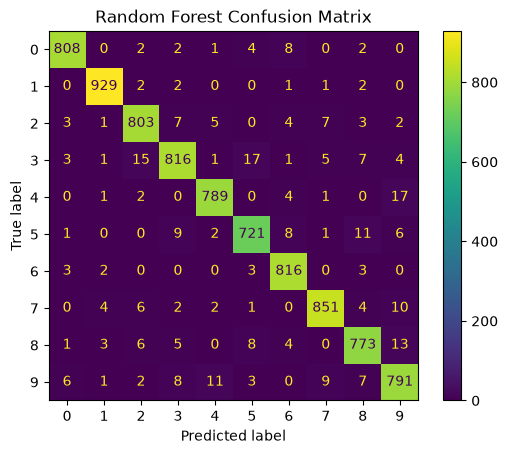

In [12]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Create the confusion matrix display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

# Display the confusion matrix
disp.plot()

# Add a title
plt.title("Random Forest Confusion Matrix")

# Show the plot
plt.show()

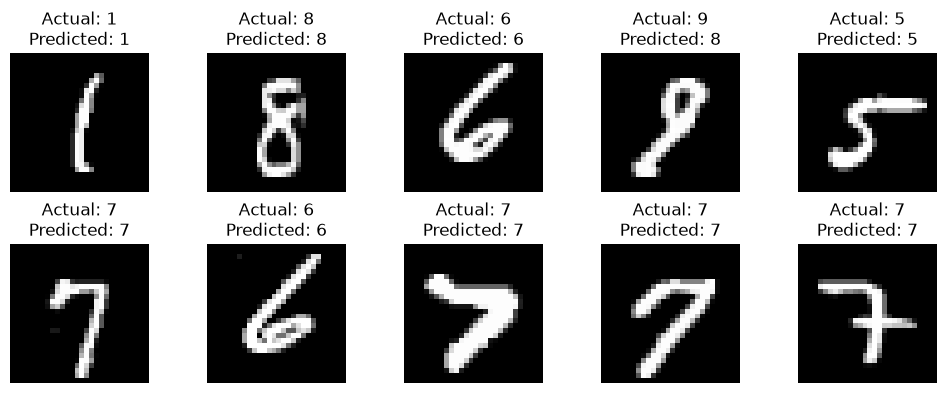

In [13]:
# Create a figure for displaying 10 test images
plt.figure(figsize=(10, 4))

# Display the first 10 test images
for i in range(10):

    # Convert the 784 pixel values back into
    # a 28 × 28 image
    image = X_test.iloc[i].values.reshape(28, 28)

    # Create a subplot
    plt.subplot(2, 5, i + 1)

    # Display the handwritten digit
    plt.imshow(image, cmap="gray")

    # Display actual and predicted labels
    plt.title(
        f"Actual: {y_test.iloc[i]}\n"
        f"Predicted: {y_pred_rf[i]}"
    )

    # Hide the axis
    plt.axis("off")

# Adjust spacing
plt.tight_layout()

# Display the images
plt.show()

In [14]:
# Import joblib for saving the trained model
import joblib

# Save the Random Forest model
joblib.dump(rf_model, "random_forest_digit_model.pkl")

# Confirm that the model was saved
print("Random Forest model saved successfully!")

Random Forest model saved successfully!
